# LeetCode #62: Unique Paths

https://leetcode.com/problems/unique-paths/

## Three ways to solve it

| Approach | Time | Space | What that means in practice |
| :--- | :--- | :--- | :--- |
| **Brute force: walk every path** | $O(2^{m+n})$ | $O(m+n)$ | Counts paths one at a time; a 17×17 grid has 601 million of them. |
| **A table of path counts** | $O(m \times n)$ | $O(m \times n)$ | One small addition per square: 10,000 for a 100×100 grid. |
| **Count the arrangements directly ★** | $O(\min(m, n))$ | $O(1)$ | At most 16 multiplications for any grid LeetCode allows. |

`m` is the number of rows and `n` the number of columns. $O(m \times n)$ means **the work grows with the
number of squares**. $O(\min(m,n))$ means it grows only with the shorter side. $O(1)$ means a fixed
handful of numbers, whatever the grid size.

The robot starts in the top-left square and must reach the bottom-right one, moving only **right** or
**down**. A **path** is one such sequence of moves.

## Understanding the methods

### Brute force

From each square, try going right and try going down, and count every route that arrives. It recounts
the same partial routes over and over, and the number of paths itself grows explosively.

### A table of path counts

Let `dp[r][c]` be the number of paths that reach square `(r, c)`. The last move into a square came from
above or from the left, so `dp[r][c] = dp[r-1][c] + dp[r][c-1]`, with every square on the top row and left
column equal to 1. Filling answers from smaller stored answers is **dynamic programming**. It can be cut to
one row of memory, since each row only reads the row above.

### Optimal: count the arrangements directly ★ (the one coded below)

Every path is exactly `m - 1` downs and `n - 1` rights, in some order. So a path is just a choice of which
of the `m + n - 2` moves are the downs. That's the **binomial coefficient** $\binom{m+n-2}{m-1}$, read "m+n−2
choose m−1": the number of ways to pick `m - 1` items from `m + n - 2`.

**Why this beats the table:** the table's corner *is* this number (the table builds Pascal's triangle), so
computing it directly skips the other squares entirely.

**Constraints:**
* `1 <= m, n <= 100`
* The test cases are generated so that the answer will be less than or equal to `2 * 10^9`


## Explain Like I'm a Newbie

### What the question is actually asking

A robot sits in the top-left square of an `m`-row, `n`-column grid. It can only step right or down. How
many different routes reach the bottom-right square?

```
3 rows x 3 columns:   R R D D    R D R D    R D D R
                      D R R D    D R D R    D D R R      6 routes
```

### The one idea you need: every square adds up the two ways into it

Think about the very last step into any square. It came from the square above or the square to its left.
No route can do both, so:

> **`dp[r][c]` = the number of routes that reach square `(r, c)` = routes to the square above + routes to
> the square on the left.**

The top row and left column are all 1: there's only one way to slide straight along an edge. Fill the rest
row by row and the bottom-right box is the answer. That's **dynamic programming**: build each answer from
smaller ones already worked out.

### The shortcut the code takes

Every route has the same moves, just shuffled: exactly `m - 1` downs and `n - 1` rights. For the 3×7 grid
that's 2 downs and 6 rights, 8 moves. A route is completely described by *which* 2 of the 8 moves are the
downs, so the answer is "8 choose 2" = 28. Python has this built in as `math.comb(8, 2)`. The table above
produces exactly these numbers, so both ideas agree.

The other three languages compute it with a loop: start at 1, then repeatedly multiply by the next number
from the top and divide by the next number from the bottom: $1 \times 8 \div 1 = 8$, then $8 \times 7 \div 2 = 28$.

### Mistakes people make the first time

1. **Dividing before multiplying.** `result / (i + 1) * (total - i)` passes both of LeetCode's samples
   (3×7 and 3×2), then answers 8 instead of 10 on a 3×4 grid, because the early division throws away a
   remainder.
2. **Doing the loop in 32-bit integers.** Also passes both samples. On a 69×8 grid the product before
   dividing reaches 13.9 billion, past the 32-bit limit, and the answer comes out wrong even though the
   real answer fits.
3. **Swapping rows and columns.** Harmless here, since choosing the downs or the rights gives the same
   number, but the table version must index `dp[row][col]` consistently.

### Things worth knowing

Multiplying first, then dividing, always gives a whole number: after step `i` the running value is itself
a choose number. LeetCode caps answers at 2 × 10^9, which is what keeps the 64-bit intermediate safe.


## Talking It Through in an Interview

*Written from the interviewer's chair. This is what I'd want to hear from you, from the moment I show you the problem to the moment the code is on the board.*

---

### The 30-second pitch

> **You:** "Paths into a square come from above or from the left, so a table where each box is above plus left gives the answer in m times n steps. But every path is the same multiset of moves, m minus 1 downs and n minus 1 rights, so the count is just which positions the downs take: m plus n minus 2 choose m minus 1. I compute that with a multiply-then-divide loop over the shorter side, in 64-bit, which stays exact because each partial result is itself a binomial. The thing it leans on is the answer cap; without it, the numbers outgrow any fixed-size integer."

Both ideas, the table and the formula, and why one becomes the other. That's what I'd hope to hear in the first minute.

---

### I slide the problem across the table

I draw a 3 by 7 grid with a robot in the corner and ask how many paths reach the opposite corner.

> **You:** "Only right and down moves? No obstacles?"

**"Right and down only, no obstacles."** That second answer is what makes the formula legal. If I'd said obstacles, you'd be doing the table, and I'm glad you checked before reaching for combinatorics.

> **You:** "Up to 100 by 100? That number would be huge."

**"Up to 100 each, but the answer is guaranteed to be at most 2 times 10 to the 9."** Good: you noticed the count can explode, and now you know the guarantee you're leaning on.

---

### Now tell me what's actually hard about it

> **You:** "Enumerating paths is hopeless; even a 17 by 17 grid has 600 million. And a recursive count from each square recomputes the same sub-counts again and again. But the count for a square only depends on where you are, not how you got there. The last move into it came from above or from the left, and those are separate groups of paths, so I add them."

That's the hard part named: the paths overlap, the squares don't. Then I usually ask, "can you avoid the table?"

> **You:** "Every path is exactly 2 downs and 6 rights here, 8 moves. The only difference between paths is where the 2 downs go. So it's 8 choose 2, 28. The table is building Pascal's triangle, and the corner is that entry."

The table first, then the formula, with a reason connecting them. Candidates who jump straight to the formula often can't handle the follow-up with obstacles.

---

### Before you touch the board, tell me the shape and the cost

> **You:** "In Python, `math.comb(m + n - 2, m - 1)`. In a language without it, a loop: k is the smaller of m minus 1 and n minus 1, total is m plus n minus 2, start result at 1, and for i from 0 to k minus 1, multiply by total minus i, then divide by i plus 1.
>
> That's min(m, n) minus 1 multiplications. Under your cap, the largest square grid is 17 by 17, so at most 16 steps. The table would be m times n additions, up to 10,000."

Deriving the 16 from the cap is better than reciting "O(min(m, n))". It shows you used my answer.

---

### Now whiteboard it

```
long result = 1;
int k = Math.Min(m - 1, n - 1);
int total = m + n - 2;
```

> **You:** "Choosing the downs or the rights gives the same number, so I pick whichever makes the loop shorter. And result is a 64-bit long, because the product before dividing can pass 2 billion even when the answer doesn't."

If you write `int result` and say nothing, I'll ask you for 69 by 8. The product before the last division is 13.9 billion.

```
for (int i = 0; i < k; i++)
    result = result * (total - i) / (i + 1);
return (int)result;
```

> **You:** "Multiply first, then divide. After step i, result equals total choose i plus 1, so the division is always exact. Divide first and a remainder gets thrown away: a 3 by 4 grid comes out 8 instead of 10."

That order is the line I watch. Both of LeetCode's samples pass with it backwards.

---

### Walk me through it before you say you're done

> **You:** "3 by 7: k is 2, total is 8. Step 0: 1 times 8 over 1, 8. Step 1: 8 times 7 over 2, 28. Returns 28."

> **You:** "And a single row, m equals 1: k is 0, the loop never runs, the answer is 1. There's one path, straight along."

The single-row case ties back to the shape, which is what I want. The table version needs its edges set to 1 for exactly the same reason.

---

### Then tell me where it breaks, before I ask

> **You:** "Inside your limits, nothing: at most 16 multiplications and a few variables. It leans on two things. The answer cap, because without it 100 by 100 is about 10 to the 58, and no fixed-size integer holds that; I'd need big integers. Python's `math.comb` already uses them, so the Python version would simply return a 58-digit number; the C#, Go and Rust versions would overflow silently or panic. And the 'no obstacles' answer: the formula only works because every arrangement of the moves is a legal path."

> **You:** "If you add obstacles, that's the table again: a blocked square is 0, everything else is above plus left. And I'd keep one row, since each row only reads the row above, so memory is n numbers."

That's the generalisation I'd have asked for next. And knowing that the formula is a special case of the table, not a different idea, is what tells me you'll handle it.

---

### What would worry me

A 32-bit accumulator. Division before multiplication. Recursion with no memory on a 17 by 17 grid. And quoting the binomial without being able to say why it counts paths, because that candidate is stuck the moment I add a rock to the grid.


## Solutions

All four compute $\binom{m+n-2}{m-1}$: the number of ways to choose which of the `m + n - 2` moves are the `m - 1` downs.

### C#


In [ ]:
public class Solution {
    public int UniquePaths(int m, int n) {
        // Every path is (m-1) downs and (n-1) rights in some order. A path is fixed by
        // WHICH of the m+n-2 moves are downs, so the answer is C(m+n-2, m-1).
        // C(total, a) == C(total, b) when a + b = total, so loop over the shorter side.
        // 64-bit on purpose: the product below can pass 2^31 even when the answer doesn't.
        long result = 1;
        int k = Math.Min(m - 1, n - 1);
        int total = m + n - 2;

        for (int i = 0; i < k; i++) {
            // Multiply FIRST, then divide: result becomes C(total, i+1), a whole number,
            // so the division is exact. Dividing first would throw away a remainder.
            result = result * (total - i) / (i + 1);
        }

        return (int)result;   // fits: LeetCode caps the answer at 2 * 10^9
    }
}

### Python

`math.comb` (Python 3.8+) returns the exact binomial coefficient using Python's unlimited-size integers, so there is nothing to overflow.


In [ ]:
import math

class Solution:
    def uniquePaths(self, m: int, n: int) -> int:
        # Every path is (m-1) downs and (n-1) rights in some order. A path is fixed by
        # WHICH of the m+n-2 moves are downs, so the answer is C(m+n-2, m-1).
        return math.comb(m + n - 2, m - 1)

### Go


In [ ]:
func uniquePaths(m int, n int) int {
    // Every path is (m-1) downs and (n-1) rights in some order. A path is fixed by
    // WHICH of the m+n-2 moves are downs, so the answer is C(m+n-2, m-1).
    // C(total, a) == C(total, b) when a + b = total, so loop over the shorter side.
    // Go's int is 64-bit on LeetCode, so the product below has room to pass 2^31.
    result := 1
    k := m - 1
    if n-1 < k {
        k = n - 1
    }
    total := m + n - 2

    for i := 0; i < k; i++ {
        // Multiply FIRST, then divide: result becomes C(total, i+1), a whole number,
        // so the division is exact. Dividing first would throw away a remainder.
        result = result * (total - i) / (i + 1)
    }

    return result
}

### Rust


In [ ]:
impl Solution {
    pub fn unique_paths(m: i32, n: i32) -> i32 {
        // Every path is (m-1) downs and (n-1) rights in some order. A path is fixed by
        // WHICH of the m+n-2 moves are downs, so the answer is C(m+n-2, m-1).
        // C(total, a) == C(total, b) when a + b = total, so loop over the shorter side.
        // i64 on purpose: the product below can pass 2^31 even when the answer doesn't.
        let mut result: i64 = 1;
        let k = (m - 1).min(n - 1) as i64;
        let total = (m + n - 2) as i64;

        for i in 0..k {
            // Multiply FIRST, then divide: result becomes C(total, i+1), a whole number,
            // so the division is exact. Dividing first would throw away a remainder.
            result = result * (total - i) / (i + 1);
        }

        result as i32   // fits: LeetCode caps the answer at 2 * 10^9
    }
}

## Example Scenarios

### 1. Common Case — LeetCode's 3 × 7 Grid
**Input:** `m = 3, n = 7`

Every path is 8 moves, 2 down and 6 right, so the answer is the number of ways to pick which 2 moves are
downs: $\binom{8}{2} = 28$. The loop runs twice: $1 \times 8 \div 1 = 8$, then $8 \times 7 \div 2 = 28$.
**Output:** `28`

### 2. Slightly Complex — The Same Grid on Its Side
**Input:** `m = 7, n = 3`

Now it's 6 downs and 2 rights. Picking the 2 rights gives the same count as picking the 6 downs, so the code
loops over the smaller number and the answer is again $\binom{8}{2}$. **Output:** `28`

### 3. Edge Case: Time Factor — The Longest Loop Allowed
**Input:** `m = 17, n = 17`

LeetCode caps answers at $2 \times 10^9$, and 17 × 17 is the largest square grid under that cap (18 × 18
gives about 2.3 billion), so 16 loop steps is the most any valid input needs. Several products before
dividing pass the 32-bit limit, which is why the loop uses 64-bit numbers. **Output:** `601080390`

### 4. Edge Case: Space Factor — A Single Row
**Input:** `m = 1, n = 100`

Only right moves are possible, so there's exactly one path and the loop runs zero times. The formula keeps
a couple of numbers for every grid, so no input is harder on memory than another. **Output:** `1`

### 5. Almost-Impossible but Plausible — The Biggest Answer Allowed
**Input:** `m = 69, n = 8`

Of every grid up to 100 × 100, this one's answer comes closest to the $2 \times 10^9$ cap. The answer fits in
32 bits, but the last product before dividing is about 13.9 billion, which doesn't: a 32-bit loop gets this
one wrong. **Output:** `1984829850`


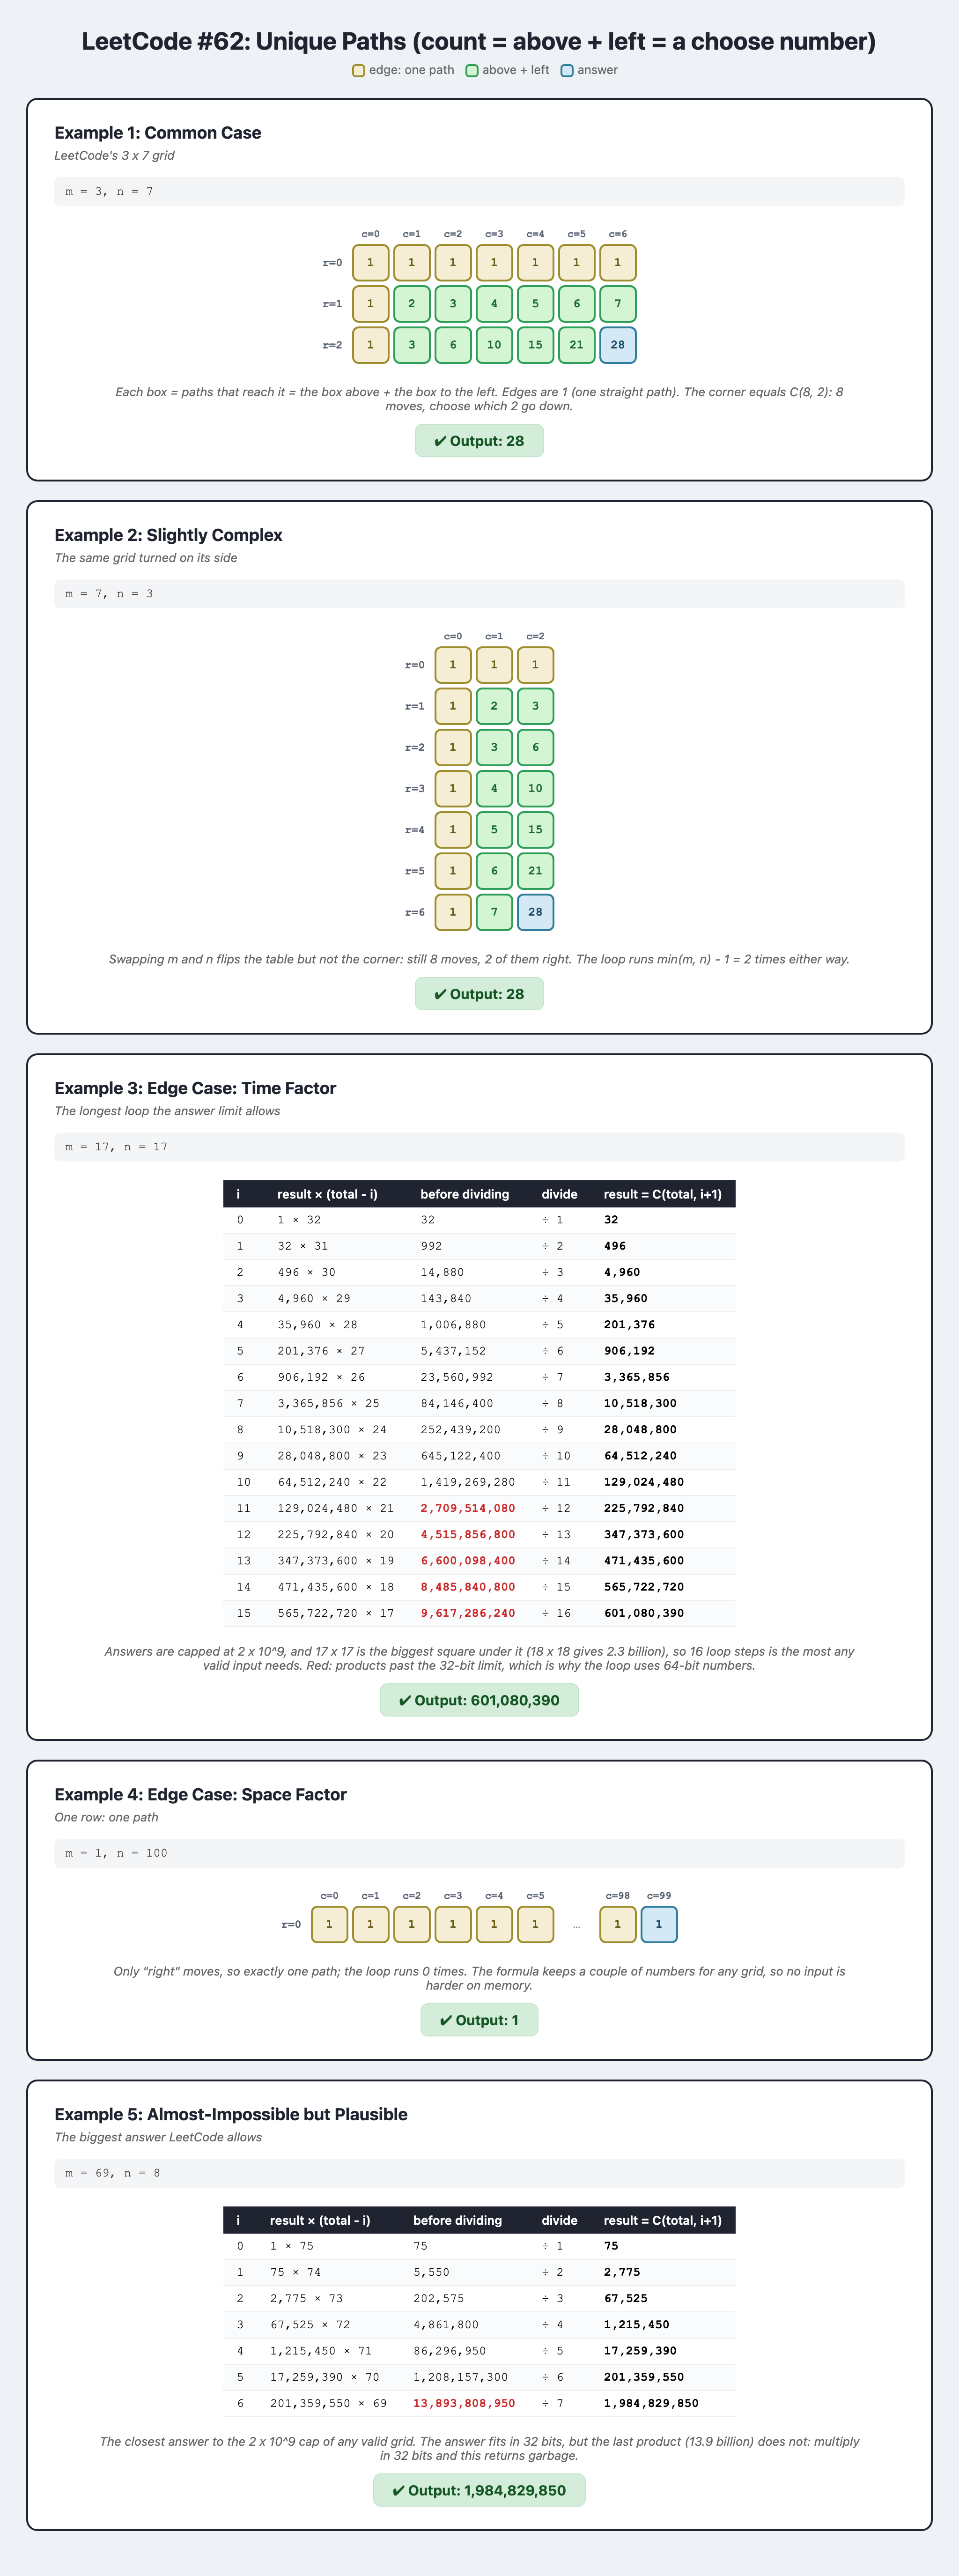

## Watch It Run

*Watch square (1,1): its 2 is the 1 above plus the 1 to its left, and that same 'above + left' rule builds the corner's 28.*

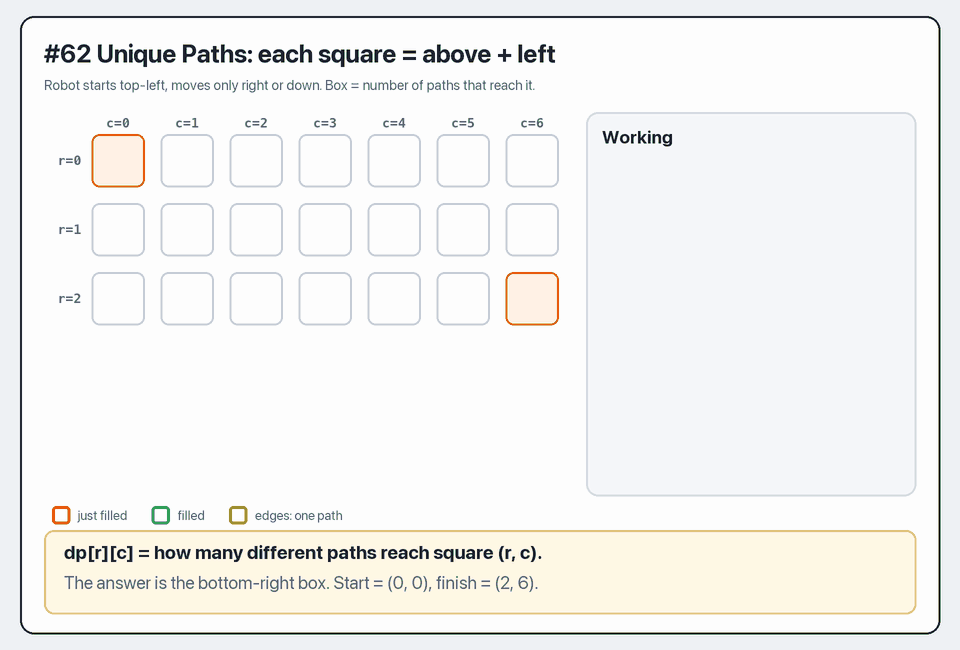

**[Step through it yourself: play, pause, scrub and step through this walkthrough, plus a harder example](https://sanjay-bhat.github.io/ProgrammingConcepts/walkthroughs/0062.html)**